# EN3160 Assignment 3 - Neural Networks

**Student name:** `Dilhara.D.S`  
**Index number:** `230147L`  
**GitHub profile:** `https://github.com/sachi1645/Neural-Networks`

This notebook implements the three tasks in the assignment: a manually differentiated two-layer CIFAR-10 network, two 10-epoch MNIST CNN experiments, and two ResNet18 transfer-learning strategies on Hymenoptera.

## 1. Setup and reproducibility

The experiments use PyTorch and torchvision. The code automatically selects CUDA when available, fixes random seeds, saves result figures/CSVs to `results/` and uses `num_workers=0` for compatibility with Windows notebooks.

In [1]:
from pathlib import Path
import os, random, time, zipfile, urllib.request, copy, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

c:\Users\dilha\Desktop\Resource-Constrained-CNN-MNIST\.venv\Lib\site-packages\torch\cuda\__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = Path(r'C:\Users\dilha\Desktop\Neural-Networks\Data')
RESULTS_DIR = Path(r'C:\Users\dilha\Desktop\Neural-Networks\Results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
NUM_WORKERS = 0  
print('PyTorch:', torch.__version__)
print('torchvision:', torchvision.__version__)
print('Device:', DEVICE)

PyTorch: 2.10.0+cu126
torchvision: 0.25.0+cu126
Device: cuda


# Question 1 - CIFAR-10 dense network with manual backpropagation

The supplied listing uses CIFAR-10 images flattened to 3072 values. This implementation adds a hidden layer of 100 sigmoid units and uses categorical cross-entropy. The forward pass, softmax-cross-entropy derivative, and weight/bias updates are written explicitly; autograd is not used for this model.

For a minibatch, the network is

\[
Z_1=XW_1+b_1,\quad H=\sigma(Z_1),\quad Z_2=HW_2+b_2.
\]

For logits \(Z_2\), the derivative of mean cross-entropy is \(dZ_2=(\operatorname{softmax}(Z_2)-Y)/B\). The remaining gradients follow the chain rule; \(dZ_1=(dZ_2W_2^T)\odot H\odot(1-H)\). The hidden layer and cross-entropy are both part of the required changes.

In [3]:
CIFAR_BATCH_SIZE = 128
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
cifar_train = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=cifar_transform)
cifar_train_loader = DataLoader(cifar_train, batch_size=CIFAR_BATCH_SIZE, shuffle=True,
                                num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
cifar_test_loader = DataLoader(cifar_test, batch_size=CIFAR_BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
CIFAR_CLASSES = cifar_train.classes
print(f'CIFAR-10: {len(cifar_train):,} training images, {len(cifar_test):,} test images')
print('Classes:', CIFAR_CLASSES)

100%|██████████| 170M/170M [15:53<00:00, 179kB/s]  


CIFAR-10: 50,000 training images, 10,000 test images
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
class ManualTwoLayerMLP:
    """3072 -> 100 sigmoid -> 10 logits; gradients are calculated manually."""
    def __init__(self, input_dim=3*32*32, hidden_dim=100, num_classes=10, device=DEVICE):
        self.W1 = (torch.randn(input_dim, hidden_dim, device=device) * np.sqrt(1.0 / input_dim))
        self.b1 = torch.zeros(hidden_dim, device=device)
        self.W2 = (torch.randn(hidden_dim, num_classes, device=device) * np.sqrt(1.0 / hidden_dim))
        self.b2 = torch.zeros(num_classes, device=device)

    def forward(self, x):
        z1 = x @ self.W1 + self.b1
        h = torch.sigmoid(z1)
        logits = h @ self.W2 + self.b2
        return logits, h

    def train_batch(self, x, y, lr=0.1, reg=1e-4):
        batch_size = x.shape[0]
        logits, h = self.forward(x)
        # Stable mean cross-entropy from logits.
        log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        loss = -log_probs.gather(1, y[:, None]).mean()
        loss = loss + 0.5 * reg * (self.W1.square().sum() + self.W2.square().sum())

        # Manual derivative of softmax + cross-entropy.
        probs = torch.softmax(logits, dim=1)
        probs[torch.arange(batch_size, device=y.device), y] -= 1.0
        dZ2 = probs / batch_size
        dW2 = h.T @ dZ2 + reg * self.W2
        db2 = dZ2.sum(dim=0)
        dH = dZ2 @ self.W2.T
        dZ1 = dH * h * (1.0 - h)  # derivative of sigmoid
        dW1 = x.T @ dZ1 + reg * self.W1
        db1 = dZ1.sum(dim=0)

        # Plain tensor updates 
        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2
        return float(loss.detach().item())

    @torch.no_grad()
    def predict(self, x):
        return self.forward(x)[0].argmax(dim=1)


def evaluate_manual_mlp(model, loader):
    total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True).reshape(images.shape[0], -1)
            labels = labels.to(DEVICE, non_blocking=True)
            logits, _ = model.forward(images)
            loss = F.cross_entropy(logits, labels, reduction='sum')
            loss_sum += float(loss.item())
            correct += int((logits.argmax(1) == labels).sum().item())
            total += labels.numel()
    return loss_sum / total, 100.0 * correct / total

Epoch 01/10 | loss=1.8766 | lr=0.10000
Epoch 02/10 | loss=1.7460 | lr=0.09000
Epoch 03/10 | loss=1.7011 | lr=0.08100
Epoch 04/10 | loss=1.6723 | lr=0.07290
Epoch 05/10 | loss=1.6493 | lr=0.06561
Epoch 06/10 | loss=1.6302 | lr=0.05905
Epoch 07/10 | loss=1.6156 | lr=0.05314
Epoch 08/10 | loss=1.6012 | lr=0.04783
Epoch 09/10 | loss=1.5901 | lr=0.04305
Epoch 10/10 | loss=1.5790 | lr=0.03874


,model,epochs,train_loss,train_accuracy_percent,test_loss,test_accuracy_percent,training_time_seconds
0,Manual MLP (3072-100-sigmoid-10),10,1.559,46.862,1.6088,44.62,117.3167


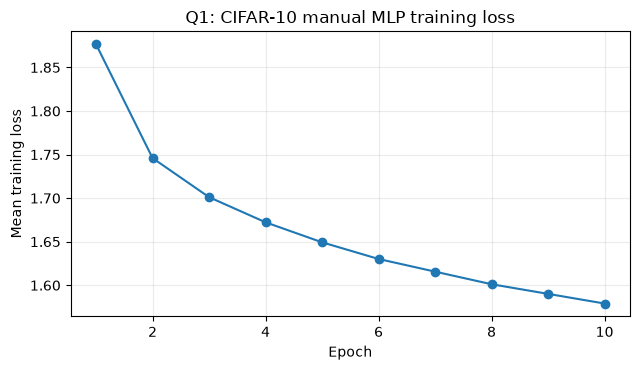

In [5]:
# Train for exactly 10 epochs, reporting training and test accuracy at the end.
Q1_EPOCHS = 10
mlp = ManualTwoLayerMLP()
q1_history = {'epoch': [], 'mean_minibatch_train_loss': []}
start = time.time()
for epoch in range(Q1_EPOCHS):
    lr = 0.1 * (0.9 ** epoch)
    running_loss, seen = 0.0, 0
    for images, labels in cifar_train_loader:
        images = images.to(DEVICE, non_blocking=True).reshape(images.shape[0], -1)
        labels = labels.to(DEVICE, non_blocking=True)
        loss = mlp.train_batch(images, labels, lr=lr)
        running_loss += loss * labels.size(0)
        seen += labels.size(0)
    epoch_loss = running_loss / seen
    q1_history['epoch'].append(epoch + 1)
    q1_history['mean_minibatch_train_loss'].append(epoch_loss)
    print(f'Epoch {epoch+1:02d}/{Q1_EPOCHS} | loss={epoch_loss:.4f} | lr={lr:.5f}')

q1_train_loss, q1_train_acc = evaluate_manual_mlp(mlp, cifar_train_loader)
q1_test_loss, q1_test_acc = evaluate_manual_mlp(mlp, cifar_test_loader)
q1_seconds = time.time() - start
q1_results = pd.DataFrame([{
    'model': 'Manual MLP (3072-100-sigmoid-10)', 'epochs': Q1_EPOCHS,
    'train_loss': q1_train_loss, 'train_accuracy_percent': q1_train_acc,
    'test_loss': q1_test_loss, 'test_accuracy_percent': q1_test_acc,
    'training_time_seconds': q1_seconds
}])
display(q1_results.round(4))
q1_results.to_csv(RESULTS_DIR / 'q1_cifar10_summary.csv', index=False)
pd.DataFrame(q1_history).to_csv(RESULTS_DIR / 'q1_cifar10_epoch_loss.csv', index=False)

plt.figure(figsize=(6.5, 3.8))
plt.plot(q1_history['epoch'], q1_history['mean_minibatch_train_loss'], marker='o')
plt.xlabel('Epoch'); plt.ylabel('Mean training loss')
plt.title('Q1: CIFAR-10 manual MLP training loss'); plt.grid(alpha=0.25); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'q1_cifar10_training_loss.png', dpi=180)
plt.show()

### Q1 interpretation

Use the measured train/test accuracies above in the final write-up. A train accuracy appreciably above test accuracy indicates overfitting; both low indicates that this shallow fully connected model is underfitting the image task. Flattening discards local spatial structure, and sigmoid units can saturate, so this small MLP is expected to be weaker than convolutional architectures. The cross-entropy derivative is applied to logits, which avoids an unnecessary separate softmax layer in the loss calculation.

# Question 2 - LeNet-5 and a modern three-convolution CNN on MNIST

Both networks use the same MNIST train/test split, normalization, batch size, optimizer, and 10-epoch schedule. The notebook records train/test loss and accuracy after each epoch and saves a confusion matrix from the test predictions for each model.

In [10]:
MNIST_BATCH_SIZE = 64
MNIST_EPOCHS = 10
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])
mnist_train = datasets.MNIST(root=str(DATA_DIR), train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(root=str(DATA_DIR), train=False, download=True, transform=mnist_transform)

def make_mnist_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(mnist_train, batch_size=MNIST_BATCH_SIZE, shuffle=True,
                              generator=generator, num_workers=NUM_WORKERS,
                              pin_memory=(DEVICE.type == 'cuda'))
    test_loader = DataLoader(mnist_test, batch_size=256, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
    return train_loader, test_loader

mnist_train_loader, mnist_test_loader = make_mnist_loaders()
print(f'MNIST: {len(mnist_train):,} training images, {len(mnist_test):,} test images')

100%|██████████| 1.65M/1.65M [00:01<00:00, 964kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 785kB/s]

MNIST: 60,000 training images, 10,000 test images


In [11]:
class LeNet5(nn.Module):
    """LeNet-5 style network for 28x28 grayscale MNIST images."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2),
        )  # 28 -> 24 -> 12 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 4 * 4, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class SmallModernCNN(nn.Module):
    """Exactly three convolution layers, with batch normalization and dropout."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.Dropout2d(0.10), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.Dropout2d(0.15), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )  # convolution feature-map sizes: 28 -> 14 -> 7 -> 7
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            count = labels.size(0)
            total_loss += loss.item() * count
            total_correct += (logits.argmax(1) == labels).sum().item()
            total += count
    return total_loss / total, 100.0 * total_correct / total


def fit_classifier(model, train_loader, test_loader, epochs, name, learning_rate=0.01):
    model = model.to(DEVICE)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9, weight_decay=1e-4)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        te_loss, te_acc = run_epoch(model, test_loader, optimizer=None)
        history.append({'epoch': epoch, 'train_loss': tr_loss, 'train_accuracy_percent': tr_acc,
                        'test_loss': te_loss, 'test_accuracy_percent': te_acc})
        print(f'{name} | epoch {epoch:02d}/{epochs} | '
              f'train loss {tr_loss:.4f}, acc {tr_acc:.2f}% | '
              f'test loss {te_loss:.4f}, acc {te_acc:.2f}%')
    result = pd.DataFrame(history)
    result.to_csv(RESULTS_DIR / f'{name.lower()}_history.csv', index=False)
    print(f'{name} training time: {(time.time()-start)/60:.1f} min')
    return model, result


@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    all_true, all_pred = [], []
    for images, labels in loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(logits.argmax(1).cpu().numpy().tolist())
    return np.asarray(all_true), np.asarray(all_pred)


def plot_history(history, name):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='Train')
    axes[0].plot(history['epoch'], history['test_loss'], marker='o', label='Test')
    axes[0].set(title=f'{name}: loss', xlabel='Epoch', ylabel='Cross-entropy loss')
    axes[0].grid(alpha=0.25); axes[0].legend()
    axes[1].plot(history['epoch'], history['train_accuracy_percent'], marker='o', label='Train')
    axes[1].plot(history['epoch'], history['test_accuracy_percent'], marker='o', label='Test')
    axes[1].set(title=f'{name}: accuracy', xlabel='Epoch', ylabel='Accuracy (%)')
    axes[1].grid(alpha=0.25); axes[1].legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{name.lower()}_learning_curves.png', dpi=180)
    plt.show()


def plot_confusion(model, loader, name):
    y_true, y_pred = collect_predictions(model, loader)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    disp = ConfusionMatrixDisplay(cm, display_labels=[str(i) for i in range(10)])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name}: MNIST test confusion matrix')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{name.lower()}_confusion_matrix.png', dpi=180)
    plt.show()
    return cm

LeNet5_MNIST | epoch 01/10 | train loss 0.4020, acc 88.60% | test loss 0.1096, acc 96.73%
LeNet5_MNIST | epoch 02/10 | train loss 0.0915, acc 97.30% | test loss 0.0613, acc 97.98%
LeNet5_MNIST | epoch 03/10 | train loss 0.0623, acc 98.14% | test loss 0.0469, acc 98.48%
LeNet5_MNIST | epoch 04/10 | train loss 0.0516, acc 98.44% | test loss 0.0421, acc 98.56%
LeNet5_MNIST | epoch 05/10 | train loss 0.0441, acc 98.64% | test loss 0.0382, acc 98.67%
LeNet5_MNIST | epoch 06/10 | train loss 0.0387, acc 98.83% | test loss 0.0367, acc 98.77%
LeNet5_MNIST | epoch 07/10 | train loss 0.0335, acc 98.98% | test loss 0.0366, acc 98.75%
LeNet5_MNIST | epoch 08/10 | train loss 0.0314, acc 99.03% | test loss 0.0422, acc 98.72%
LeNet5_MNIST | epoch 09/10 | train loss 0.0283, acc 99.12% | test loss 0.0319, acc 98.85%
LeNet5_MNIST | epoch 10/10 | train loss 0.0261, acc 99.20% | test loss 0.0278, acc 99.05%
LeNet5_MNIST training time: 3.1 min


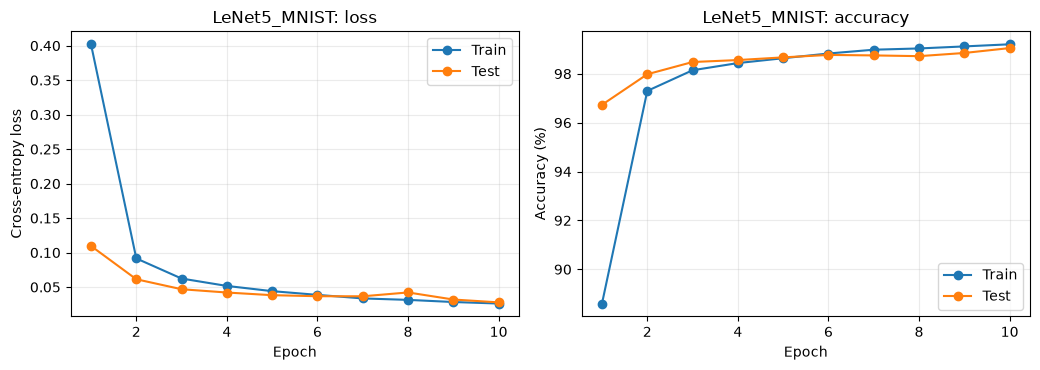

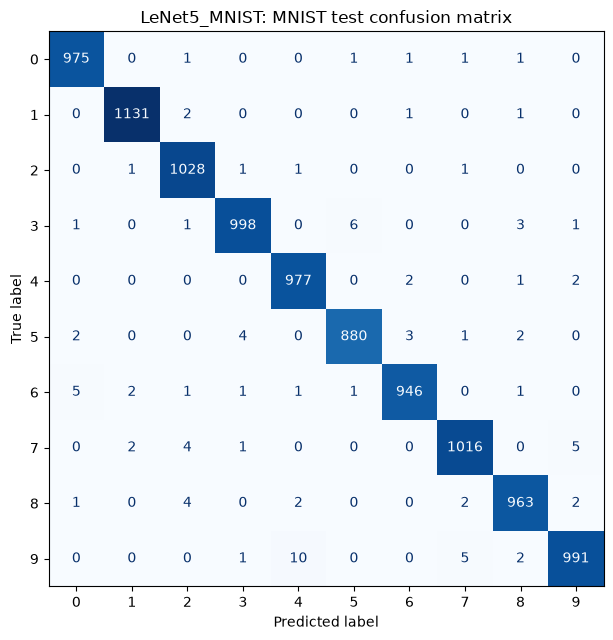

In [12]:
# Experiment 2(a): LeNet-5, exactly 10 epochs.
# Reset seeds and shuffle generator to make the comparison easier to reproduce.
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
mnist_train_loader_lenet, mnist_test_loader_lenet = make_mnist_loaders(seed=SEED)
lenet_model, lenet_history = fit_classifier(
    LeNet5(), mnist_train_loader_lenet, mnist_test_loader_lenet,
    epochs=MNIST_EPOCHS, name='LeNet5_MNIST', learning_rate=0.01
)
plot_history(lenet_history, 'LeNet5_MNIST')
lenet_cm = plot_confusion(lenet_model, mnist_test_loader_lenet, 'LeNet5_MNIST')

ModernCNN_MNIST | epoch 01/10 | train loss 0.9504, acc 69.92% | test loss 0.2057, acc 95.95%
ModernCNN_MNIST | epoch 02/10 | train loss 0.2960, acc 91.64% | test loss 0.1023, acc 97.55%
ModernCNN_MNIST | epoch 03/10 | train loss 0.1916, acc 94.61% | test loss 0.0782, acc 97.87%
ModernCNN_MNIST | epoch 04/10 | train loss 0.1507, acc 95.67% | test loss 0.0595, acc 98.28%
ModernCNN_MNIST | epoch 05/10 | train loss 0.1315, acc 96.19% | test loss 0.0550, acc 98.44%
ModernCNN_MNIST | epoch 06/10 | train loss 0.1149, acc 96.70% | test loss 0.0504, acc 98.54%
ModernCNN_MNIST | epoch 07/10 | train loss 0.1067, acc 96.94% | test loss 0.0440, acc 98.76%
ModernCNN_MNIST | epoch 08/10 | train loss 0.0959, acc 97.21% | test loss 0.0417, acc 98.83%
ModernCNN_MNIST | epoch 09/10 | train loss 0.0924, acc 97.32% | test loss 0.0384, acc 98.92%
ModernCNN_MNIST | epoch 10/10 | train loss 0.0856, acc 97.57% | test loss 0.0376, acc 98.95%
ModernCNN_MNIST training time: 3.3 min


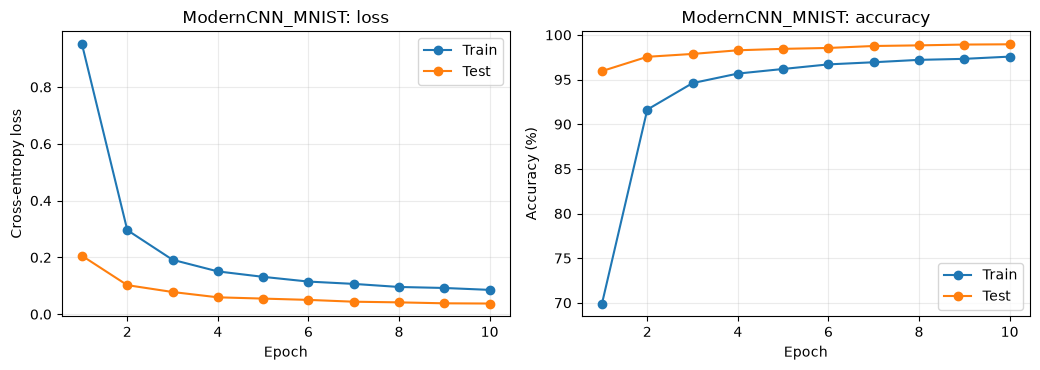

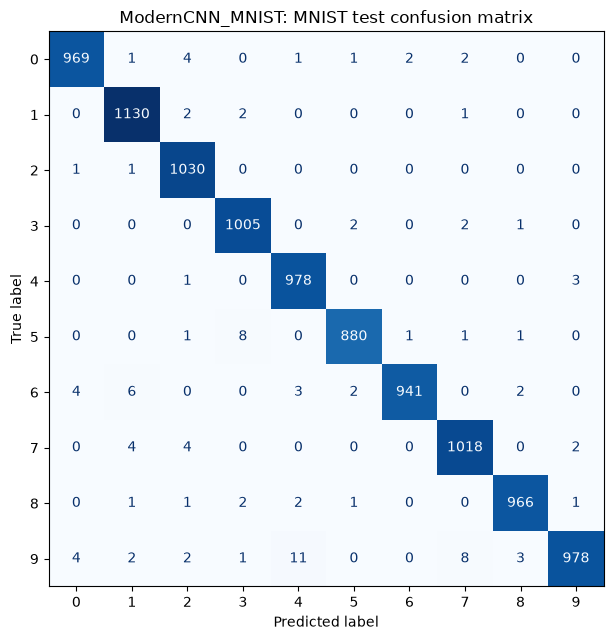

In [13]:
# Experiment 2(b): modern 3-convolution CNN, same MNIST data and 10 epochs.
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
mnist_train_loader_cnn, mnist_test_loader_cnn = make_mnist_loaders(seed=SEED)
modern_model, modern_history = fit_classifier(
    SmallModernCNN(), mnist_train_loader_cnn, mnist_test_loader_cnn,
    epochs=MNIST_EPOCHS, name='ModernCNN_MNIST', learning_rate=0.01
)
plot_history(modern_history, 'ModernCNN_MNIST')
modern_cm = plot_confusion(modern_model, mnist_test_loader_cnn, 'ModernCNN_MNIST')

In [14]:
# Final comparison after epoch 10. Use measured numbers; do not copy expected values.
q2_comparison = pd.DataFrame([
    {'model': 'LeNet-5', 'epochs': MNIST_EPOCHS,
     'final_train_accuracy_percent': float(lenet_history.iloc[-1]['train_accuracy_percent']),
     'final_test_accuracy_percent': float(lenet_history.iloc[-1]['test_accuracy_percent']),
     'final_train_loss': float(lenet_history.iloc[-1]['train_loss']),
     'final_test_loss': float(lenet_history.iloc[-1]['test_loss'])},
    {'model': 'Modern 3-layer CNN + BN + dropout', 'epochs': MNIST_EPOCHS,
     'final_train_accuracy_percent': float(modern_history.iloc[-1]['train_accuracy_percent']),
     'final_test_accuracy_percent': float(modern_history.iloc[-1]['test_accuracy_percent']),
     'final_train_loss': float(modern_history.iloc[-1]['train_loss']),
     'final_test_loss': float(modern_history.iloc[-1]['test_loss'])},
])
display(q2_comparison.round(4))
q2_comparison.to_csv(RESULTS_DIR / 'q2_mnist_model_comparison.csv', index=False)

,model,epochs,final_train_accuracy_percent,final_test_accuracy_percent,final_train_loss,final_test_loss
0,LeNet-5,10,99.205,99.05,0.0261,0.0278
1,Modern 3-layer CNN + BN + dropout,10,97.570,98.95,0.0856,0.0376


### Q2 interpretation guide

Discuss (i) which model attains the higher test accuracy after epoch 10, (ii) whether the gap between training and test accuracy suggests overfitting, and (iii) the most commonly confused digit pairs in the confusion matrices. LeNet-5 uses tanh activations and average pooling in a compact classic architecture. The modern model uses three convolutional layers, batch normalization, ReLU, max pooling, and dropout; batch normalization can stabilize optimization and dropout can reduce co-adaptation. State the measured results rather than assuming one model must win.

# Question 3 - Transfer learning with ImageNet-pretrained ResNet18

The same training/validation image folders are used for both approaches. Fine tuning makes the entire backbone trainable. Feature extraction freezes the pretrained convolutional backbone and trains only the replacement two-class fully connected layer. Both are evaluated on the validation split each epoch, and the final validation accuracy and number of trainable parameters are reported.

In [ ]:
HYMENOPTERA_URL = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
HYMENOPTERA_DIR = DATA_DIR / 'hymenoptera_data'


def ensure_hymenoptera_data():
    """Use a local tutorial folder if present; otherwise download/extract the official tutorial archive."""
    if (HYMENOPTERA_DIR / 'train').is_dir() and (HYMENOPTERA_DIR / 'val').is_dir():
        return HYMENOPTERA_DIR
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive_path = DATA_DIR / 'hymenoptera_data.zip'
    try:
        print('Downloading Hymenoptera dataset...')
        urllib.request.urlretrieve(HYMENOPTERA_URL, archive_path)
        with zipfile.ZipFile(archive_path, 'r') as zf:
            zf.extractall(DATA_DIR)
    except Exception as exc:
        raise RuntimeError(
            'Hymenoptera data are not available locally and could not be downloaded. '
            'Connect to the internet or extract hymenoptera_data.zip into ./data/hymenoptera_data/ '
            'with train/ and val/ subfolders, then rerun this cell. Original error: ' + str(exc)
        ) from exc
    if not ((HYMENOPTERA_DIR / 'train').is_dir() and (HYMENOPTERA_DIR / 'val').is_dir()):
        raise FileNotFoundError('Expected data/hymenoptera_data/{train,val} after extraction.')
    return HYMENOPTERA_DIR


def make_hymenoptera_loaders(batch_size=8):
    data_dir = ensure_hymenoptera_data()
    # Use the normalization statistics associated with the specified ImageNet-1K weights.
    weight_metadata = ResNet18_Weights.IMAGENET1K_V1
    mean, std = weight_metadata.transforms().mean, weight_metadata.transforms().std
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize(mean, std),
    ])
    val_transform = transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224),
        transforms.ToTensor(), transforms.Normalize(mean, std),
    ])
    image_datasets = {
        'train': datasets.ImageFolder(str(data_dir / 'train'), transform=train_transform),
        'val': datasets.ImageFolder(str(data_dir / 'val'), transform=val_transform),
    }
    if image_datasets['train'].classes != image_datasets['val'].classes:
        raise ValueError('Training and validation folders have different class names/order.')
    loaders = {
        split: DataLoader(ds, batch_size=batch_size, shuffle=(split == 'train'),
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
        for split, ds in image_datasets.items()
    }
    print('Hymenoptera classes:', image_datasets['train'].classes)
    print('Training images:', len(image_datasets['train']), '| Validation images:', len(image_datasets['val']))
    return image_datasets, loaders

hymenoptera_datasets, hymenoptera_loaders = make_hymenoptera_loaders(batch_size=8)

In [ ]:
def make_resnet18_transfer(feature_extractor=False):
    """Load ImageNet-1K ResNet18 weights and replace its output layer for two classes."""
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    if feature_extractor:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 2)
    # The newly initialized layer always remains trainable.
    for param in model.fc.parameters():
        param.requires_grad = True
    return model.to(DEVICE)


def fit_transfer(model, loaders, epochs=10, learning_rate=0.001, label='ResNet18', freeze_backbone=False):
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.SGD(trainable, lr=learning_rate, momentum=0.9)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        row = {'epoch': epoch}
        for phase in ('train', 'val'):
            model.train(phase == 'train')
            # For feature extraction, keep the frozen backbone (including BatchNorm
            # running statistics) in evaluation mode while training only the FC head.
            if phase == 'train' and freeze_backbone:
                model.eval()
                model.fc.train()
            total_loss, correct, total = 0.0, 0, 0
            context = torch.enable_grad() if phase == 'train' else torch.no_grad()
            with context:
                for inputs, labels in loaders[phase]:
                    inputs = inputs.to(DEVICE, non_blocking=True)
                    labels = labels.to(DEVICE, non_blocking=True)
                    if phase == 'train':
                        optimizer.zero_grad(set_to_none=True)
                    outputs = model(inputs)
                    loss = F.cross_entropy(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                    count = labels.size(0)
                    total_loss += loss.item() * count
                    correct += (outputs.argmax(1) == labels).sum().item()
                    total += count
            row[f'{phase}_loss'] = total_loss / total
            row[f'{phase}_accuracy_percent'] = 100.0 * correct / total
        history.append(row)
        print(f'{label} | epoch {epoch:02d}/{epochs} | '
              f'train loss {row["train_loss"]:.4f}, acc {row["train_accuracy_percent"]:.2f}% | '
              f'val loss {row["val_loss"]:.4f}, acc {row["val_accuracy_percent"]:.2f}%')
    result = pd.DataFrame(history)
    result.to_csv(RESULTS_DIR / f'{label.lower()}_history.csv', index=False)
    print(f'{label} training time: {(time.time()-start)/60:.1f} min')
    return model, result


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_transfer_history(history, label):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    axes[0].plot(history.epoch, history.train_loss, marker='o', label='Train')
    axes[0].plot(history.epoch, history.val_loss, marker='o', label='Validation')
    axes[0].set(title=f'{label}: loss', xlabel='Epoch', ylabel='Cross-entropy loss')
    axes[0].grid(alpha=0.25); axes[0].legend()
    axes[1].plot(history.epoch, history.train_accuracy_percent, marker='o', label='Train')
    axes[1].plot(history.epoch, history.val_accuracy_percent, marker='o', label='Validation')
    axes[1].set(title=f'{label}: accuracy', xlabel='Epoch', ylabel='Accuracy (%)')
    axes[1].grid(alpha=0.25); axes[1].legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{label.lower()}_learning_curves.png', dpi=180)
    plt.show()

In [ ]:
# Experiment 3(a): fine tune all ResNet18 layers.
Q3_EPOCHS = 10
fine_tune_model = make_resnet18_transfer(feature_extractor=False)
print('Fine-tuning trainable parameters:', f'{count_trainable_parameters(fine_tune_model):,}')
fine_tune_model, fine_tune_history = fit_transfer(
    fine_tune_model, hymenoptera_loaders, epochs=Q3_EPOCHS,
    learning_rate=0.001, label='ResNet18_FineTuning'
)
plot_transfer_history(fine_tune_history, 'ResNet18_FineTuning')

In [ ]:
# Experiment 3(b): freeze the pretrained backbone; train only the fc layer.
feature_model = make_resnet18_transfer(feature_extractor=True)
print('Feature-extractor trainable parameters:', f'{count_trainable_parameters(feature_model):,}')
feature_model, feature_history = fit_transfer(
    feature_model, hymenoptera_loaders, epochs=Q3_EPOCHS,
    learning_rate=0.001, label='ResNet18_FeatureExtractor', freeze_backbone=True
)
plot_transfer_history(feature_history, 'ResNet18_FeatureExtractor')

In [ ]:
q3_comparison = pd.DataFrame([
    {'method': 'Fine tuning', 'trainable_parameters': count_trainable_parameters(fine_tune_model),
     'epochs': Q3_EPOCHS, 'final_train_accuracy_percent': float(fine_tune_history.iloc[-1]['train_accuracy_percent']),
     'final_validation_accuracy_percent': float(fine_tune_history.iloc[-1]['val_accuracy_percent']),
     'final_validation_loss': float(fine_tune_history.iloc[-1]['val_loss'])},
    {'method': 'Feature extractor (frozen backbone)', 'trainable_parameters': count_trainable_parameters(feature_model),
     'epochs': Q3_EPOCHS, 'final_train_accuracy_percent': float(feature_history.iloc[-1]['train_accuracy_percent']),
     'final_validation_accuracy_percent': float(feature_history.iloc[-1]['val_accuracy_percent']),
     'final_validation_loss': float(feature_history.iloc[-1]['val_loss'])},
])
display(q3_comparison.round(4))
q3_comparison.to_csv(RESULTS_DIR / 'q3_resnet18_comparison.csv', index=False)

### Q3 interpretation

Compare validation accuracy and loss after the same number of epochs. Fine tuning updates the full network and can adapt low-, middle-, and high-level filters to ants and bees, but it uses more computation and can overfit a small dataset. Feature extraction freezes the ImageNet backbone, so only the new two-class layer learns; it is faster and needs fewer trainable parameters, but its representation cannot adapt during training. Discuss the actual measured validation results and curves; neither method should be declared the winner without those results.